<a href="https://colab.research.google.com/github/dudekulapeeravali2537sse-bot/ITA0616/blob/main/EXP_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CAR DATASET
   Year  Present_Price  Kms_Driven Fuel_Type  Selling_Price
0  2015            5.5       30000    Petrol            4.5
1  2016            6.0       25000    Diesel            5.0
2  2017            7.0       20000    Petrol            5.8
3  2018            8.5       15000    Diesel            7.0
4  2019            9.0       10000    Petrol            7.5

ACTUAL VS PREDICTED PRICES
   Actual Price  Predicted Price
0           4.5         4.094220
1           8.5         8.309531
2           4.5         4.486943
3           5.0         4.675132

MODEL PERFORMANCE
Mean Absolute Error: 0.23
Mean Squared Error: 0.08
Root Mean Squared Error: 0.28
R2 Score: 0.97


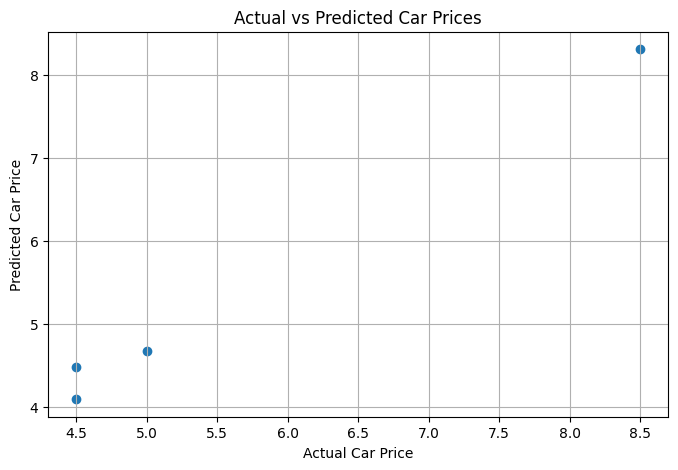


NEW CAR DETAILS
   Year  Present_Price  Kms_Driven  Fuel_Type_Petrol
0  2019            9.0       15000                 0

Predicted Car Selling Price: Rs. 7.82 Lakhs


In [2]:

# CAR PRICE PREDICTION USING MACHINE LEARNING

# Step 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Step 2: Create Dataset
data = {
    'Year': [2015, 2016, 2017, 2018, 2019,
             2015, 2016, 2017, 2018, 2020,
             2014, 2015, 2017, 2019, 2021,
             2016, 2018, 2019, 2020, 2022],

    'Present_Price': [5.5, 6.0, 7.0, 8.5, 9.0,
                      4.5, 5.0, 6.5, 7.5, 10.0,
                      3.5, 4.0, 6.0, 8.0, 12.0,
                      5.5, 8.0, 9.5, 11.0, 15.0],

    'Kms_Driven': [30000, 25000, 20000, 15000, 10000,
                   50000, 40000, 35000, 30000, 12000,
                   60000, 55000, 40000, 20000, 10000,
                   45000, 25000, 18000, 15000, 5000],

    'Fuel_Type': ['Petrol', 'Diesel', 'Petrol', 'Diesel', 'Petrol',
                  'Petrol', 'Diesel', 'Petrol', 'Diesel', 'Petrol',
                  'Petrol', 'Diesel', 'Petrol', 'Diesel', 'Petrol',
                  'Petrol', 'Diesel', 'Petrol', 'Diesel', 'Petrol'],

    'Selling_Price': [4.5, 5.0, 5.8, 7.0, 7.5,
                      3.5, 4.0, 5.5, 6.5, 9.0,
                      2.5, 3.0, 5.0, 7.0, 10.5,
                      4.5, 7.0, 8.5, 10.0, 14.0]
}

df = pd.DataFrame(data)

print("CAR DATASET")
print(df.head())

# Step 3: Data Preprocessing
df = pd.get_dummies(df, columns=['Fuel_Type'], drop_first=True)

# Step 4: Separate Features and Target
X = df.drop('Selling_Price', axis=1)
y = df['Selling_Price']

# Step 5: Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 6: Create Linear Regression Model
model = LinearRegression()

# Step 7: Train Model
model.fit(X_train, y_train)

# Step 8: Predict Car Prices
y_pred = model.predict(X_test)

print("\nACTUAL VS PREDICTED PRICES")
results = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})
print(results)

# Step 9: Evaluate Model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nMODEL PERFORMANCE")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 2))

# Step 10: Visualize Actual vs Predicted Prices
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Car Price")
plt.ylabel("Predicted Car Price")
plt.title("Actual vs Predicted Car Prices")
plt.grid(True)
plt.show()

# Step 11: Predict Price of a New Car
# Example: 2019 model, price 9 lakh,
# 15000 km driven, Diesel car (meaning Fuel_Type_Petrol is False/0)

new_car = pd.DataFrame({
    'Year': [2019],
    'Present_Price': [9.0],
    'Kms_Driven': [15000],
    'Fuel_Type_Petrol': [0]
})

predicted_price = model.predict(new_car)

print("\nNEW CAR DETAILS")
print(new_car)

print("\nPredicted Car Selling Price: Rs.",
      round(predicted_price[0], 2), "Lakhs")